# RetailMind AI - Day 11: VAE Image Augmentation

Goal: make fake images for a category the classifier struggles with, add them to the training data, and check whether that category's accuracy improves.

Steps:
1. Pick the weak category (from the Day 6 confusion matrix)
2. Train a VAE on that category
3. Look at the generated images and keep only the realistic ones
4. Add them to the training set and re-measure per-class accuracy
5. Note the change

## 1. Imports

In [1]:
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
from IPython.display import display

keras.utils.set_random_seed(42)

here = Path.cwd().resolve()
PROJECT_ROOT = here.parent if here.name == 'notebooks' else here
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUT_DIR = MODELS_DIR / 'day11_augmentation_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

I0000 00:00:1795531482.818574   65827 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795531482.881299   65827 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795531484.394157   65827 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Load the data and pick the weak category

In Day 6, the confusion matrix showed that **Shirt** was confused with T-shirt/top, Pullover and Coat the most. So Shirt is our weak category.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# scale pixels to 0-1 and add a channel dimension
x_train = x_train.astype('float32')[..., np.newaxis] / 255.0
x_test = x_test.astype('float32')[..., np.newaxis] / 255.0

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
TARGET = 6   # Shirt
print('Weak category:', class_names[TARGET])

Weak category: Shirt


## 3. Make Shirt a thin category

Fashion-MNIST has the same number of images for every class. To copy the real situation, we keep only **600 Shirts** and up to **3000** of every other class.

In [3]:
x_parts = []
y_parts = []
for c in range(10):
    images = x_train[y_train == c]
    keep = 600 if c == TARGET else 3000
    x_parts.append(images[:keep])
    y_parts.append(np.full(keep, c))

x_thin = np.concatenate(x_parts)
y_thin = np.concatenate(y_parts)

# shuffle
order = np.random.permutation(len(x_thin))
x_thin = x_thin[order]
y_thin = y_thin[order]

real_shirts = x_train[y_train == TARGET][:600]
print('Training images:', len(x_thin))
print('Real Shirts:', len(real_shirts))

Training images: 27600
Real Shirts: 600


## 4. A small helper to show images bigger

In [4]:
def show_images(images, rows, cols, scale, filename):
    # put the images into one grid picture
    row_pictures = []
    for r in range(rows):
        row_pictures.append(np.concatenate(images[r * cols:(r + 1) * cols], axis=1))
    grid = np.concatenate(row_pictures, axis=0)

    picture = keras.utils.array_to_img(grid)
    picture = picture.resize((picture.width * scale, picture.height * scale))
    picture.save(OUTPUT_DIR / filename)
    display(picture)

Real Shirt images:


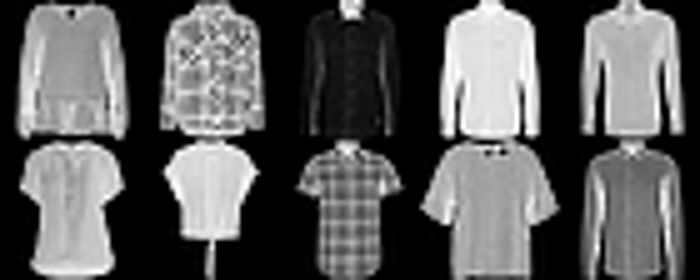

In [5]:
print('Real Shirt images:')
show_images(real_shirts, rows=2, cols=5, scale=5, filename='real_shirts.png')

## 5. Build the VAE

- The **encoder** turns an image into 16 numbers (a mean and a spread for each, so 32 outputs).
- The **decoder** turns 16 numbers back into an image.
- After training, we feed random numbers into the decoder to get new images.

In [6]:
LATENT = 16

encoder = keras.Sequential([
    keras.layers.Input((28, 28, 1)),
    keras.layers.Flatten(),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dense(LATENT * 2),
])

decoder = keras.Sequential([
    keras.layers.Input((LATENT,)),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dense(784, activation='sigmoid'),
    keras.layers.Reshape((28, 28, 1)),
])

W0000 00:00:1795531526.662494   65827 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1795531526.663682   65827 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3072 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:1c.0, compute capability: 7.5


## 6. Train the VAE on the 600 real Shirts

In [7]:
optimizer = keras.optimizers.Adam(1e-3)
data = tf.data.Dataset.from_tensor_slices(real_shirts).shuffle(600).batch(32)
variables = encoder.trainable_variables + decoder.trainable_variables

for epoch in range(50):
    for batch in data:
        with tf.GradientTape() as tape:
            mean, log_var = tf.split(encoder(batch), 2, axis=1)
            z = mean + tf.exp(0.5 * log_var) * tf.random.normal(tf.shape(mean))
            rebuilt = decoder(z)

            # how different is the rebuilt image from the original
            rebuild_loss = tf.reduce_mean(
                tf.reduce_sum(keras.losses.binary_crossentropy(batch, rebuilt), axis=(1, 2)))
            # keeps the 16 numbers close to a normal distribution so random numbers work later
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + log_var - tf.square(mean) - tf.exp(log_var), axis=1))
            loss = rebuild_loss + kl_loss

        grads = tape.gradient(loss, variables)
        optimizer.apply_gradients(zip(grads, variables))

    if (epoch + 1) % 10 == 0:
        print('Epoch', epoch + 1, '- loss:', round(float(loss), 2))

Epoch 10 - loss: 335.56
Epoch 20 - loss: 292.56
Epoch 30 - loss: 303.05
Epoch 40 - loss: 318.19
Epoch 50 - loss: 284.9


## 7. Generate new Shirt images

Generated: 1000
First 20 generated images:


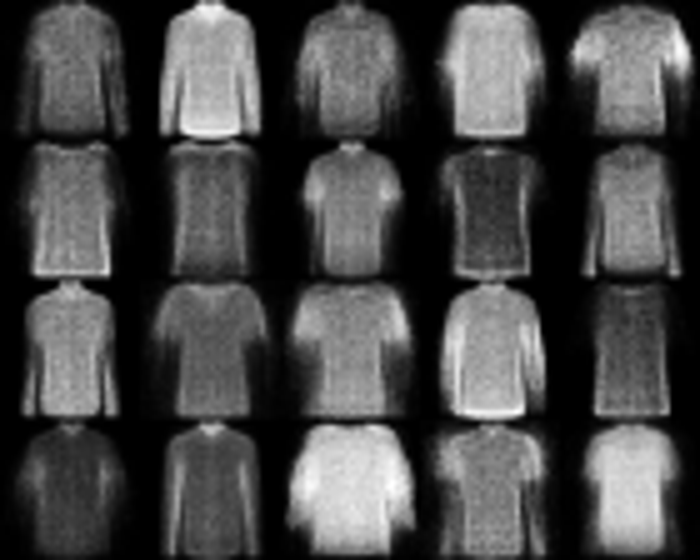

In [8]:
random_numbers = tf.random.normal((1000, LATENT))
fake_shirts = decoder(random_numbers).numpy()

print('Generated:', len(fake_shirts))
print('First 20 generated images:')
show_images(fake_shirts, rows=4, cols=5, scale=5, filename='generated_shirts.png')

## 8. Keep only the realistic images

Some generated images will be too dark, too bright or too blank. A simple check: keep an image only if its average brightness is similar to the real Shirts (between the 5th and 95th percentile of the real ones).

Kept 300 of 1000 generated images
Kept images:


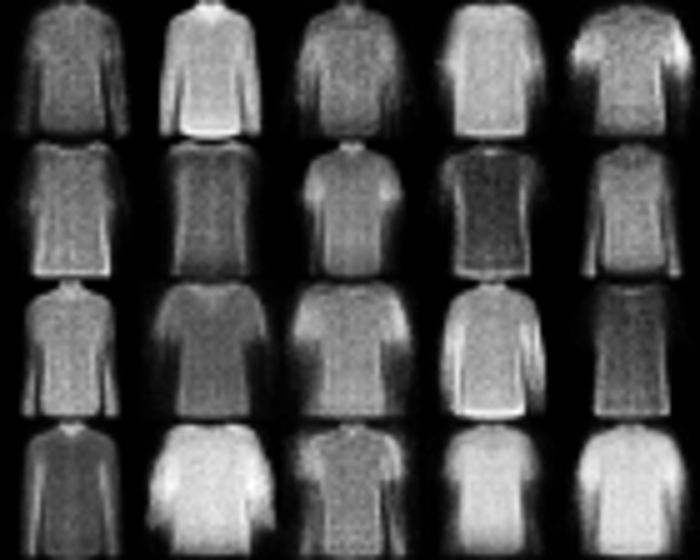

In [9]:
real_brightness = real_shirts.mean(axis=(1, 2, 3))
fake_brightness = fake_shirts.mean(axis=(1, 2, 3))

low, high = np.percentile(real_brightness, [5, 95])
realistic = (fake_brightness >= low) & (fake_brightness <= high)

good_shirts = fake_shirts[realistic][:300]
print('Kept', len(good_shirts), 'of', len(fake_shirts), 'generated images')

print('Kept images:')
show_images(good_shirts, rows=4, cols=5, scale=5, filename='kept_shirts.png')

## 9. Classifier before augmentation

Same small CNN both times, with the same starting seed, so the only difference is the extra images.

In [10]:
def build_classifier():
    keras.utils.set_random_seed(42)
    model = keras.Sequential([
        keras.layers.Input((28, 28, 1)),
        keras.layers.Conv2D(32, 3, activation='relu'),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation='relu'),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(10, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def class_accuracy(model):
    predictions = model.predict(x_test, verbose=0).argmax(axis=1)
    return [float((predictions[y_test == c] == c).mean()) for c in range(10)]

before_model = build_classifier()
before_model.fit(x_thin, y_thin, epochs=5, batch_size=64, verbose=0)

before = class_accuracy(before_model)
before_overall = float(before_model.evaluate(x_test, y_test, verbose=0)[1])
print('Overall accuracy before:', round(before_overall, 4))
print('Shirt accuracy before:  ', round(before[TARGET], 4))

I0000 00:00:1795531648.666880   66197 service.cc:153] XLA service 0x7f94600318d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795531648.666899   66197 service.cc:161]   StreamExecutor [0]: Tesla T4, Compute Capability 7.5 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1795531648.692583   66197 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795531648.860329   66197 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1795531648.873278   66197 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_419844__.30
I0000 00:00:1795531651.549708   66197 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1795531653.010255   66200 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_419844__.30


Overall accuracy before: 0.8507
Shirt accuracy before:   0.167


## 10. Classifier after adding the kept synthetic Shirts

In [11]:
x_aug = np.concatenate([x_thin, good_shirts])
y_aug = np.concatenate([y_thin, np.full(len(good_shirts), TARGET)])

order = np.random.permutation(len(x_aug))
x_aug = x_aug[order]
y_aug = y_aug[order]

after_model = build_classifier()
after_model.fit(x_aug, y_aug, epochs=5, batch_size=64, verbose=0)

after = class_accuracy(after_model)
after_overall = float(after_model.evaluate(x_test, y_test, verbose=0)[1])
print('Overall accuracy after:', round(after_overall, 4))
print('Shirt accuracy after:  ', round(after[TARGET], 4))

I0000 00:00:1795531669.831364   66197 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_434059__.30
I0000 00:00:1795531672.189018   66199 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_434059__.30


Overall accuracy after: 0.8603
Shirt accuracy after:   0.218


## 11. Per-class accuracy: before vs after

In [12]:
print('CLASS            BEFORE   AFTER    CHANGE')
print('-' * 45)
for c in range(10):
    change = after[c] - before[c]
    note = '  <- target' if c == TARGET else ''
    print(f'{class_names[c]:15s}  {before[c]:.4f}   {after[c]:.4f}   {change:+.4f}{note}')

print()
print('Shirt accuracy change:  ', f'{after[TARGET] - before[TARGET]:+.4f}')
print('Overall accuracy change:', f'{after_overall - before_overall:+.4f}')

CLASS            BEFORE   AFTER    CHANGE
---------------------------------------------
T-shirt/top      0.9530   0.9390   -0.0140
Trouser          0.9600   0.9750   +0.0150
Pullover         0.7610   0.8250   +0.0640
Dress            0.8640   0.9130   +0.0490
Coat             0.9220   0.8970   -0.0250
Sandal           0.9700   0.9810   +0.0110
Shirt            0.1670   0.2180   +0.0510  <- target
Sneaker          0.9710   0.9570   -0.0140
Bag              0.9820   0.9550   -0.0270
Ankle boot       0.9570   0.9430   -0.0140

Shirt accuracy change:   +0.0510
Overall accuracy change: +0.0096


## 12. Save the results

In [13]:
decoder.save(MODELS_DIR / 'day11_vae_decoder.keras')
after_model.save(MODELS_DIR / 'day11_augmented_classifier.keras')

results = {
    'target_class': class_names[TARGET],
    'real_shirts_used': 600,
    'generated': len(fake_shirts),
    'kept': len(good_shirts),
    'shirt_accuracy_before': before[TARGET],
    'shirt_accuracy_after': after[TARGET],
    'shirt_accuracy_change': after[TARGET] - before[TARGET],
    'overall_accuracy_before': before_overall,
    'overall_accuracy_after': after_overall,
    'overall_accuracy_change': after_overall - before_overall,
    'before_per_class': before,
    'after_per_class': after,
}
with open(MODELS_DIR / 'day11_augmentation_metrics.json', 'w') as f:
    json.dump(results, f, indent=2)

print('Saved models and metrics.')

Saved models and metrics.


## Summary

- **Weak category:** Shirt (from the Day 6 confusion matrix)
- **Generator:** VAE trained on 600 real Shirts
- **Quality check:** looked at the images and kept only those with realistic brightness
- **Result:** see the before/after table in section 11

**Business value:** extra training images for thin categories without collecting new photos.

**Open blocker:** this uses 28x28 Fashion-MNIST images, so VAE output is blurry. A real version would use the Kaggle Fashion Product Images dataset.